In [3]:

import cv2
import numpy as np

# Read the input image
image = cv2.imread(r"C:\Users\Rujuta\Downloads\flower.jpg")

if image is None:
    print("Image not found! Check the file name.")
    exit()

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
edges = cv2.Canny(blur, 50, 150)

# Make copies for displaying results
line_image = image.copy()
circle_image = image.copy()

# Hough Transform for straight lines
threshold = 50

lines = cv2.HoughLinesP(
    edges,
    1,
    np.pi / 180,
    threshold,
    minLineLength=30,
    maxLineGap=10
)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.reshape(-1)
        cv2.line(
            line_image, (x1, y1), (x2, y2),
            (0, 255, 0), 2
        )
    print("Number of lines detected:", len(lines))
else:
    print("No lines detected.")

# Hough Transform for circles
param2 = 30

circles = cv2.HoughCircles(
    blur,
    cv2.HOUGH_GRADIENT,
    dp=1.2,
    minDist=30,
    param1=100,
    param2=param2,
    minRadius=5,
    maxRadius=100
)

if circles is not None:
    circles = np.uint16(np.around(circles))

    for circle in circles[0, :]:
        x, y, radius = circle

        # Draw circle boundary
        cv2.circle(
            circle_image, (x, y), radius,
            (0, 255, 0), 2
        )

        # Mark the center
        cv2.circle(
            circle_image, (x, y), 3,
            (0, 0, 255), -1
        )

    print("Number of circles detected:", len(circles[0]))
else:
    print("No circles detected.")

# Display results
cv2.imshow("Original Image", image)
cv2.imshow("Detected Edges", edges)
cv2.imshow("Detected Lines", line_image)
cv2.imshow("Detected Circles", circle_image)

# Save output images
cv2.imwrite("detected_lines.jpg", line_image)
cv2.imwrite("detected_circles.jpg", circle_image)

cv2.waitKey(0)
cv2.destroyAllWindows()


Number of lines detected: 398
Number of circles detected: 239


Number of lines detected: 398
Number of circles detected: 239


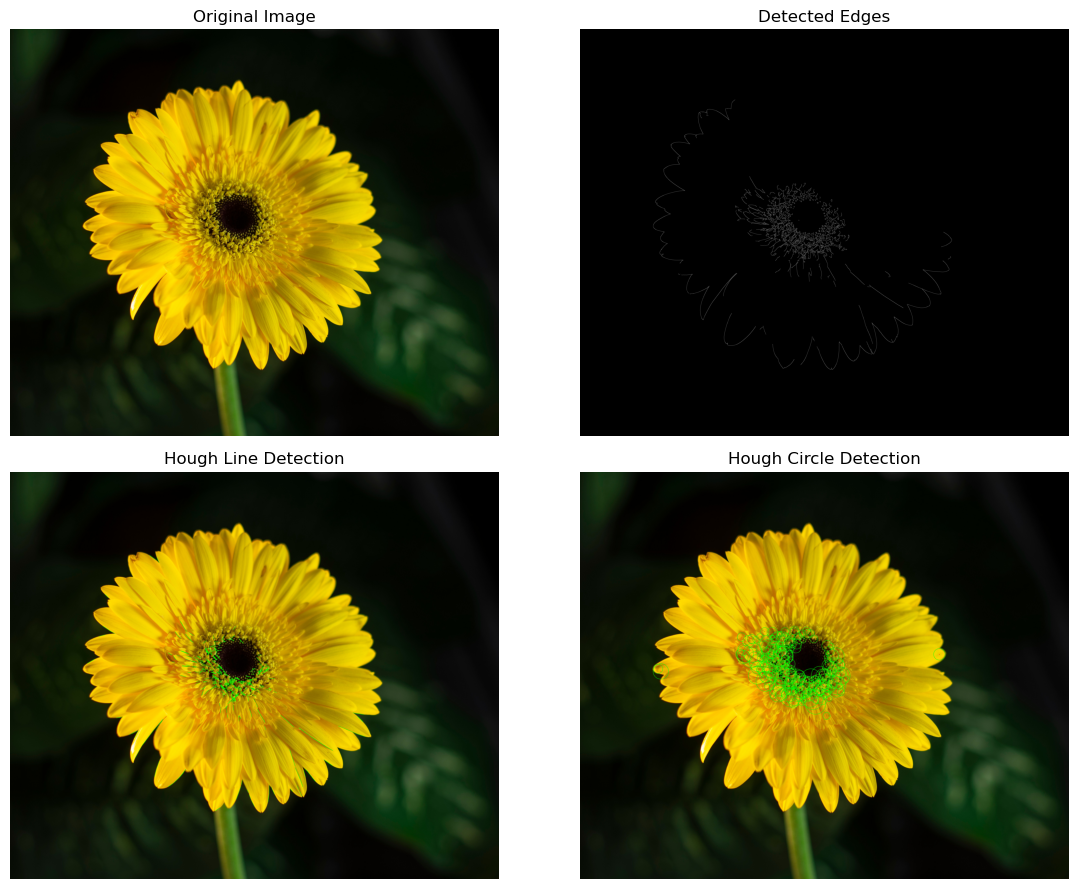

Output images saved successfully!


In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read the input image
image = cv2.imread(r"C:\Users\Rujuta\Downloads\flower.jpg")

if image is None:
    print("Image not found! Check the file name and path.")
else:
    # Step 2: Convert to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Step 3: Reduce noise
    blur = cv2.GaussianBlur(gray, (5, 5), 0)

    # Step 4: Detect edges
    edges = cv2.Canny(blur, 50, 150)

    # Copies for drawing detected shapes
    line_image = image.copy()
    circle_image = image.copy()

    # Step 5: Detect straight lines
    lines = cv2.HoughLinesP(
        edges,
        1,
        np.pi / 180,
        50,
        minLineLength=30,
        maxLineGap=10
    )

    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = np.asarray(line).reshape(-1)[:4]
            cv2.line(
                line_image,
                (int(x1), int(y1)),
                (int(x2), int(y2)),
                (0, 255, 0),
                2
            )
        print("Number of lines detected:", len(lines))
    else:
        print("No lines detected.")

    # Step 6: Detect circles
    circles = cv2.HoughCircles(
        blur,
        cv2.HOUGH_GRADIENT,
        dp=1.2,
        minDist=30,
        param1=100,
        param2=30,
        minRadius=5,
        maxRadius=100
    )

    if circles is not None:
        circles = np.uint16(np.around(circles))

        for circle in circles[0, :]:
            x, y, radius = circle

            # Draw circle boundary
            cv2.circle(
                circle_image,
                (int(x), int(y)),
                int(radius),
                (0, 255, 0),
                2
            )

            # Mark circle center
            cv2.circle(
                circle_image,
                (int(x), int(y)),
                3,
                (0, 0, 255),
                -1
            )

        print("Number of circles detected:", len(circles[0]))
    else:
        print("No circles detected.")

    # Step 7: Convert images from BGR to RGB
    original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    lines_rgb = cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB)
    circles_rgb = cv2.cvtColor(circle_image, cv2.COLOR_BGR2RGB)

    # Step 8: Display all results
    plt.figure(figsize=(12, 9))

    plt.subplot(2, 2, 1)
    plt.imshow(original_rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(edges, cmap="gray")
    plt.title("Detected Edges")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(lines_rgb)
    plt.title("Hough Line Detection")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(circles_rgb)
    plt.title("Hough Circle Detection")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # Step 9: Save output images
    cv2.imwrite("detected_edges.jpg", edges)
    cv2.imwrite("detected_lines.jpg", line_image)
    cv2.imwrite("detected_circles.jpg", circle_image)

    print("Output images saved successfully!")
